# Gradients, Jacobians, VJPs, and Hessians

**AI Mathematics · 2. Calculus**

Understand the derivative objects and vector-Jacobian products used by automatic differentiation systems.

> The emphasis is on short, reusable examples rather than long projects. Code examples use Python and NumPy unless noted otherwise.

## Learning objectives
- Distinguish gradient, Jacobian, and Hessian.
- Compute Jacobians and Hessians for small functions.
- Understand reverse-mode automatic differentiation through VJPs.

In [1]:
import numpy as np

## 1. Gradient versus Jacobian
A scalar loss \(L:\mathbb{R}^n\to\mathbb{R}\) has a gradient vector of shape \((n,)\). A vector function \(f:\mathbb{R}^n\to\mathbb{R}^m\) has a Jacobian of shape \((m,n)\). Different libraries may store gradients as row or column vectors, so always state the convention.

In [2]:
import numpy as np

def f(x):
    a, b = x
    return np.array([a*b, a**2 + b])

# Analytic Jacobian at (a,b) = (2,3)
a, b = 2.0, 3.0
J = np.array([[b, a], [2*a, 1.0]])
print(J)
print("shape:", J.shape)

[[3. 2.]
 [4. 1.]]
shape: (2, 2)


## 2. Hessian and curvature
For scalar \(f(x)\), the Hessian is the matrix of second partial derivatives. For \(f(x,y)=x^2+3xy+2y^2\), the Hessian is constant and symmetric. Positive curvature in all directions corresponds to a positive-definite Hessian and a strict local minimum for a stationary point.

In [3]:
H = np.array([[2.0, 3.0], [3.0, 4.0]])
print("Hessian:\n", H)
print("symmetric:", np.allclose(H, H.T))
print("eigenvalues:", np.linalg.eigvalsh(H))  # mixed signs => not convex everywhere

Hessian:
 [[2. 3.]
 [3. 4.]]
symmetric: True
eigenvalues: [-0.16227766  6.16227766]


## 3. Vector-Jacobian product (VJP)
Reverse-mode autodiff often computes \(v^T J_f(x)\), not the full Jacobian. If \(f\) has many outputs and a scalar loss is formed from them, a VJP efficiently propagates the loss gradient backward. With row-vector convention, the VJP is `v @ J`.

In [4]:
J = np.array([[3.0, 2.0], [4.0, 1.0]])  # 2 outputs by 2 inputs
v = np.array([0.5, -2.0])                 # upstream gradient for outputs
vjp = v @ J
print("VJP:", vjp)

# Chain rule: if L depends on f(x), then grad_x L = grad_f L @ J_f(x).

VJP: [-6.5 -1. ]


## 4. A tiny reverse-mode example
For \(z=x^2\) and \(L=3z\), the upstream derivative is \(dL/dz=3\). Backpropagation multiplies it by \(dz/dx=2x\), yielding \(dL/dx=6x\). This is a scalar version of a VJP.

In [5]:
x = 2.0
z = x**2
loss = 3*z
dL_dz = 3.0
dz_dx = 2*x
dL_dx = dL_dz * dz_dx
print("loss:", loss, "gradient:", dL_dx)

loss: 12.0 gradient: 12.0


## 5. Gradient checking
A numerical gradient can help verify an analytical gradient for a small test case. It is slow in high dimensions and unsuitable as the main training method. Discrepancies can arise from nondifferentiable points, wrong shapes, or an incorrect derivative formula.

In [6]:
def loss(w):
    return 0.5 * np.sum((w - np.array([1.0, -2.0]))**2)

def numerical_gradient(func, w, eps=1e-6):
    w = np.asarray(w, dtype=float)
    grad = np.zeros_like(w)
    for i in range(w.size):
        step = np.zeros_like(w); step[i] = eps
        grad[i] = (func(w + step) - func(w - step)) / (2*eps)
    return grad

w = np.array([0.0, 0.0])
analytic = w - np.array([1.0, -2.0])
print("analytic:", analytic)
print("numerical:", numerical_gradient(loss, w))
print("match:", np.allclose(analytic, numerical_gradient(loss, w), atol=1e-6))

analytic: [-1.  2.]
numerical: [-1.  2.]
match: True


### Choosing the right Python tool

- **NumPy** handles arrays, vectorized arithmetic, linear algebra, random sampling, and numerical operations.
- **pandas** is useful for named columns, tabular summaries, and experiment logs.
- **Matplotlib** gives low-level control over vector arrows, geometry, contour plots, and custom figures.
- **Seaborn** is built on Matplotlib and makes statistical plots such as heatmaps, distributions, and grouped comparisons quick to create.

Not every mathematical idea needs all four libraries. The extra examples use each tool where it clarifies the concept. Plots are diagnostic aids: always inspect axes, units, assumptions, and sample size.

## Visual lab: gradients are directions in parameter space

A scalar loss function over two parameters can be visualized with contour lines. The gradient points toward steepest local increase, so gradient descent moves in the opposite direction. The contour view helps explain why a single learning rate can behave differently along directions with different curvature.

07_gradients_jacobians_vjp_hessians.ipynb:cell15:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


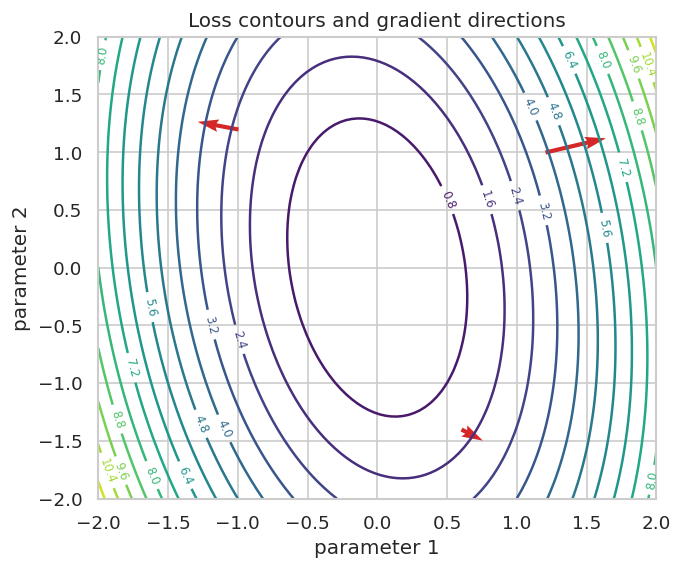

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")
def viz_grad_loss(p):
    return 2*p[0]**2 + 0.5*p[1]**2 + 0.4*p[0]*p[1]
def viz_grad(p):
    return np.array([4*p[0] + 0.4*p[1], p[1] + 0.4*p[0]])
viz_grad_axis = np.linspace(-2, 2, 100)
viz_grad_X, viz_grad_Y = np.meshgrid(viz_grad_axis, viz_grad_axis)
viz_grad_Z = 2*viz_grad_X**2 + 0.5*viz_grad_Y**2 + 0.4*viz_grad_X*viz_grad_Y
viz_grad_U, viz_grad_V = viz_grad( np.array([viz_grad_X, viz_grad_Y]) ) if False else (None, None)
fig, ax = plt.subplots(figsize=(6, 5))
cont = ax.contour(viz_grad_X, viz_grad_Y, viz_grad_Z, levels=18, cmap="viridis")
ax.clabel(cont, fontsize=7)
for p in [np.array([1.2, 1.0]), np.array([-1.0, 1.2]), np.array([0.6, -1.4])]:
    g = viz_grad(p)
    ax.quiver(p[0], p[1], g[0], g[1], angles="xy", scale_units="xy", scale=12, color="tab:red")
ax.set_xlabel("parameter 1"); ax.set_ylabel("parameter 2"); ax.set_title("Loss contours and gradient directions"); plt.show()

### Jacobian, VJP, and Hessian in one small example

For a vector-valued function, the Jacobian contains the partial derivatives of every output with respect to every input. A vector-Jacobian product \(v^T J\) can be computed without explicitly building the whole Jacobian in many autodiff systems. The Hessian is the matrix of second derivatives of a scalar function and describes local curvature.

Jacobian (rows are outputs, columns are inputs):
 [[0.3        2.        ]
 [4.         0.95533649]]
VJP v^T J: [-1.7         1.52233176]


07_gradients_jacobians_vjp_hessians.ipynb:cell17:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


,p1,p2
p1,4.0,0.4
p2,0.4,1.0


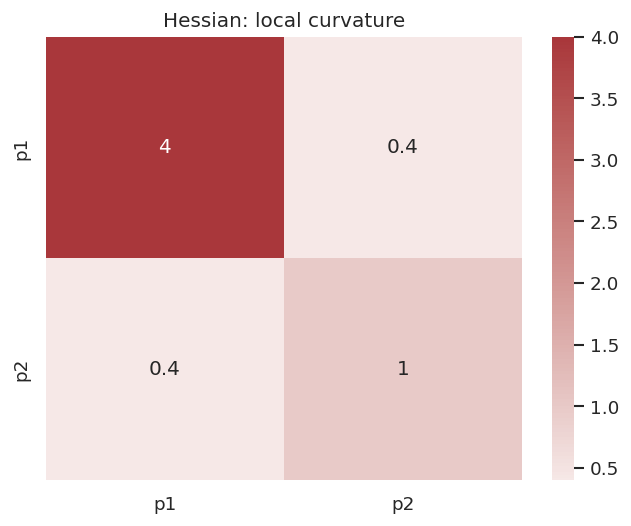

In [8]:
def viz_jacobian_fn(z):
    a, b = z
    return np.array([a*b, a**2 + np.sin(b)])
viz_jacobian_x = np.array([2.0, 0.3])
viz_jacobian_eps = 1e-6
viz_jacobian = np.column_stack([(viz_jacobian_fn(viz_jacobian_x + viz_jacobian_eps*np.eye(2)[j]) - viz_jacobian_fn(viz_jacobian_x - viz_jacobian_eps*np.eye(2)[j]))/(2*viz_jacobian_eps) for j in range(2)])
viz_vjp_v = np.array([1.0, -0.5])
print("Jacobian (rows are outputs, columns are inputs):\n", viz_jacobian)
print("VJP v^T J:", viz_vjp_v @ viz_jacobian)
viz_hessian = np.array([[4.0, 0.4], [0.4, 1.0]])
sns.heatmap(viz_hessian, annot=True, cmap="vlag", center=0, xticklabels=["p1", "p2"], yticklabels=["p1", "p2"])
plt.title("Hessian: local curvature"); plt.show()
display(pd.DataFrame(viz_hessian, index=["p1", "p2"], columns=["p1", "p2"]))

## Practice exercises
Try each exercise before looking at the suggested solution. These are intentionally small so you can change values and observe how the result changes.

### Exercise 1
Exercise 1: For f(x,y) = (xy, x+y), write its Jacobian at (2,4).

In [9]:
x, y = 2.0, 4.0
J = np.array([[y, x], [1.0, 1.0]])
print(J)

[[4. 2.]
 [1. 1.]]


### Exercise 2
Exercise 2: Compute a VJP for v=[2, -1] and J=[[1,2],[3,4]].

In [10]:
v = np.array([2.0, -1.0])
J = np.array([[1.0, 2.0], [3.0, 4.0]])
print(v @ J)

[-1.  0.]


## Key takeaways
- Gradients are derivatives of scalar losses; Jacobians describe vector-valued functions.
- Reverse-mode autodiff uses VJPs to propagate gradient information efficiently.
- Hessians describe curvature and help reason about local optimization behavior.

**Next step:** Change an input, check the shapes or assumptions, and rerun the relevant cell. That habit is central to mathematical programming.